# Ember

From day 3 of a wildfire, Ember predicts how far each of eight compass-sector
edges will advance, in kilometres, at +24 h and +72 h. A five-qubit quantum
reservoir turns recent weather and spread history into fixed features; a
ridge read-out learns the forecasts. Data: CWFIS hotspots and fire perimeters,
Canadian Forest Service.

**This notebook runs on its own.** It needs no other files, no data download
and no IBM account. The saved results, hardware measurements and figures are
embedded in the next (collapsed) cell, and the reservoir code is included below.
It needs only these Python packages:

`pip install numpy==2.5.4 pandas==3.1.1 qiskit==2.6.1 ipython`

Then run all cells.

In [1]:
# Embedded data: a compressed copy of the saved result files (results/, hardware/,
# figures/), so this notebook needs no other files. The next cell checks every
# file against its SHA-256 checksum.
BUNDLE = "..."

In [2]:
import base64
import gzip
import hashlib
import io
import json

import numpy as np
import pandas as pd
from IPython.display import Image, display

FILES = {}
for name, item in json.loads(gzip.decompress(base64.b64decode(BUNDLE))).items():
    data = base64.b64decode(item["b64"])
    assert hashlib.sha256(data).hexdigest() == item["sha256"], f"corrupted: {name}"
    FILES[name] = data

pd.set_option("display.max_rows", 50)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")

def read_json(name):
    return json.loads(FILES[name])

def read_csv(name, **options):
    return pd.read_csv(io.BytesIO(FILES[name]), **options)

def load_array(name):
    return np.load(io.BytesIO(FILES[name]), allow_pickle=False)

def show_figure(name):
    display(Image(data=FILES["figures/" + name], format="png", width=950))

def mae(y, yhat):
    """Mean absolute error over the supplied targets."""
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(yhat))))

print(f"{len(FILES)} embedded files verified; distances and errors are in km.")

28 embedded files verified; distances and errors are in km.


## Data and sector geometry

Years stay separate: train on 2018–2021, choose settings on 2022 validation,
and score 2023 test fires once. Counts below come from `results/fire_counts.json`.
Each fire has eight sectors, numbered clockwise from north.

The day-1 seed is the largest cluster of detections linked within 2 km.
Later growth follows chains within 2 km of the existing fire; daily radial
advance is capped at 30 km. The target in sector $k$ is
$$y_k^{(h)}(t)=r_k(t+h)-r_k(t),\qquad h\in\{1,3\}\text{ days}.$$
E10 checks the rebuilt final outline against the official final perimeter.

In [3]:
counts = pd.DataFrame.from_dict(read_json("results/fire_counts.json"), orient="index")
counts.index.name = "year"
display(counts[["split", "fires", "sector_rows", "origin_days"]])
display(counts.groupby("split", sort=False)[["fires"]].sum())
rebuild = read_json("results/e10_2023.json")
print(f"E10 median IoU, eight-point outline: {rebuild['median_iou']:.6f}")
print(f"E10 median IoU, buffered hotspots: {rebuild['median_iou_buffered']:.6f}")

,split,fires,sector_rows,origin_days
year,,,,
2018,train,134,43824,5076
2019,train,44,17200,2018
2020,train,7,1816,206
2021,train,193,63464,7354
2022,val,102,40552,4763
2023,test,392,171392,20248


,fires
split,
train,378
val,102
test,392


E10 median IoU, eight-point outline: 0.650093
E10 median IoU, buffered hotspots: 0.827641


## Quantum reservoir

E3 selected the window length, encoding scale, input map and ridge penalties
on validation. The circuit gates stay fixed; only the read-out is trained.
Training rows set the input min/max scaling to $[0,1]$.
Each window starts in $|00000\rangle$ and carries its state through the days:
input-dependent RY rotations, a CZ chain, then fixed RY/RZ rotations.
The saved ZF015 windows are already scaled. The next cell is the complete
reservoir code (the same as `ember/reservoir.py`). After it come the frozen
choices, the first window's circuit, and all observable names in read-out order.

In [4]:
from itertools import combinations

import numpy as np


def feature_names(n):
    """Names in read-out order: Z, lexicographic ZZ, then X."""
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError("n must be a positive integer")
    return ([f"Z{i}" for i in range(n)]
            + [f"Z{i}Z{j}" for i, j in combinations(range(n), 2)]
            + [f"X{i}" for i in range(n)])


def counts_to_features(counts: dict[str, int], n):
    """Convert Qiskit Z-basis counts to Z and ZZ expectations."""
    size = len(feature_names(n)) - n
    pairs = list(combinations(range(n), 2))
    features = np.zeros(size)
    total = 0
    for key, count in counts.items():
        bits = key.replace(" ", "")[::-1]  # The only count-key reversal.
        if len(bits) != n or any(bit not in "01" for bit in bits):
            raise ValueError(f"expected a {n}-bit count key, got {key!r}")
        if count < 0:
            raise ValueError("counts must be nonnegative")
        signs = np.array([1.0 - 2.0 * int(bit) for bit in bits])
        features[:n] += count * signs
        features[n:] += count * np.array([signs[i] * signs[j] for i, j in pairs])
        total += count
    if total <= 0:
        raise ValueError("counts must contain at least one shot")
    return features / total


def _ry(theta):
    c, s = np.cos(theta / 2), np.sin(theta / 2)
    return np.array([[c, -s], [s, c]])


class ChainReservoir:
    """Restart at zero per window; carry the state through all its days."""

    def __init__(self, n=5, gamma=np.pi / 2, seed=7,
                 entangler="cz_chain", ent_seed=None):
        feature_names(n)  # Validate the register size.
        if not np.isfinite(gamma):
            raise ValueError("gamma must be finite")
        if entangler not in ("cz_chain", "haar"):
            raise ValueError("entangler must be 'cz_chain' or 'haar'")
        self.n, self.gamma = n, float(gamma)
        self.entangler = entangler
        rng = np.random.default_rng(seed)
        self.gains = rng.uniform(0.5, 1.5, size=n)
        self.w_angles = rng.uniform(0, 2 * np.pi, size=(n, 2))
        self.gains.flags.writeable = False
        self.w_angles.flags.writeable = False

        ent_rng = np.random.default_rng(ent_seed)
        gates = []
        for _ in range(n - 1):
            if entangler == "cz_chain":
                gate = np.diag([1, 1, 1, -1]).astype(complex)
            else:
                z = (ent_rng.normal(size=(4, 4))
                     + 1j * ent_rng.normal(size=(4, 4)))
                q, r = np.linalg.qr(z)
                diagonal = np.diag(r)
                gate = q * (diagonal / np.abs(diagonal))
            gate.flags.writeable = False
            gates.append(gate)
        self._entanglers = tuple(gates)

        # Compile the fixed layer entirely in NumPy, qubit 0 leftmost.
        dim = 2 ** n
        layer = np.eye(dim, dtype=complex)
        for i, gate in enumerate(self._entanglers):
            operator = np.kron(np.kron(np.eye(2 ** i), gate),
                               np.eye(2 ** (n - i - 2)))
            layer = operator @ layer
        for i, (a, b) in enumerate(self.w_angles):
            gate = np.diag(np.exp([-0.5j * b, 0.5j * b])) @ _ry(a)
            operator = np.kron(np.kron(np.eye(2 ** i), gate),
                               np.eye(2 ** (n - i - 1)))
            layer = operator @ layer
        self._layer = layer
        indices = np.arange(dim)
        signs = 1.0 - 2.0 * ((indices[:, None] >> np.arange(n - 1, -1, -1)) & 1)
        self._z_signs = np.column_stack(
            [signs] + [signs[:, i] * signs[:, j]
                       for i, j in combinations(range(n), 2)])

    def _validate(self, values, ndim):
        values = np.asarray(values, dtype=float)
        if values.ndim != ndim or values.shape[-1] != self.n:
            shape = "(L, n)" if ndim == 2 else "(N, L, n)"
            raise ValueError(f"expected input shape {shape} with n={self.n}")
        if (not np.isfinite(values).all() or np.any(values < -1e-12)
                or np.any(values > 1 + 1e-12)):
            raise ValueError("inputs must be finite and scaled to [0, 1]")
        return values

    def circuit(self, window):
        """Build an unmeasured circuit, oldest day first."""
        from qiskit import QuantumCircuit

        window = self._validate(window, 2)
        qc = QuantumCircuit(self.n)
        for day in window:
            for i in range(self.n):
                qc.ry(self.gamma * self.gains[i] * day[i], i)
            for i, gate in enumerate(self._entanglers):
                if self.entangler == "cz_chain":
                    qc.cz(i, i + 1)
                else:
                    # Qiskit's first qarg is the low bit of this local gate.
                    qc.unitary(gate, [i + 1, i])
            for i, (a, b) in enumerate(self.w_angles):
                qc.ry(a, i)
                qc.rz(b, i)
        return qc

    def measured_circuit(self, window, basis="Z"):
        """Measure every qubit in the Z or X basis."""
        if basis not in ("Z", "X"):
            raise ValueError("basis must be 'Z' or 'X'")
        qc = self.circuit(window)
        if basis == "X":
            qc.h(range(self.n))
        qc.measure_all()
        return qc

    def features_exact(self, window):
        """Evaluate Pauli expectations using Qiskit's Statevector."""
        from qiskit.quantum_info import Pauli, Statevector

        state = Statevector.from_instruction(self.circuit(window))
        terms = ([('Z', (i,)) for i in range(self.n)]
                 + [('Z', pair) for pair in combinations(range(self.n), 2)]
                 + [('X', (i,)) for i in range(self.n)])
        features = []
        for axis, qubits in terms:
            label = ["I"] * self.n
            for i in qubits:
                label[self.n - 1 - i] = axis
            features.append(state.expectation_value(Pauli("".join(label))).real)
        return np.array(features)

    def _numpy_batch(self, windows):
        """Propagate a batch of big-endian statevectors without Qiskit."""
        count = len(windows)
        state = np.zeros((count, 2 ** self.n), dtype=complex)
        state[:, 0] = 1.0
        for day in range(windows.shape[1]):
            for i in range(self.n):
                theta = self.gamma * self.gains[i] * windows[:, day, i]
                c = np.cos(theta / 2)[:, None, None]
                s = np.sin(theta / 2)[:, None, None]
                tensor = state.reshape(count, 2 ** i, 2, 2 ** (self.n - i - 1))
                zero, one = tensor[:, :, 0, :].copy(), tensor[:, :, 1, :].copy()
                tensor[:, :, 0, :] = c * zero - s * one
                tensor[:, :, 1, :] = s * zero + c * one
            state = state @ self._layer.T
        features = np.empty((count, len(feature_names(self.n))))
        z_count = self._z_signs.shape[1]
        features[:, :z_count] = (state.real ** 2 + state.imag ** 2) @ self._z_signs
        for i in range(self.n):
            tensor = state.reshape(count, 2 ** i, 2, 2 ** (self.n - i - 1))
            features[:, z_count + i] = 2 * np.sum(
                (tensor[:, :, 0, :].conj() * tensor[:, :, 1, :]).real, axis=(1, 2))
        return features

    def features_numpy(self, window):
        """Compute all observables with the pure-NumPy validation twin."""
        window = self._validate(window, 2)
        return self._numpy_batch(window[None, ...])[0]

    def _sampled_matrix(self, windows, shots, seed, noise_model=None):
        from qiskit import transpile
        from qiskit_aer import AerSimulator

        if not isinstance(shots, (int, np.integer)) or shots <= 0:
            raise ValueError("shots must be a positive integer")
        size = len(feature_names(self.n)) - self.n
        if not len(windows):
            return np.empty((0, size))
        simulator = AerSimulator(noise_model=noise_model, max_parallel_threads=1)
        circuits = [self.measured_circuit(w) for w in windows]
        circuits = transpile(circuits, simulator, seed_transpiler=seed)
        result = simulator.run(circuits, shots=int(shots), seed_simulator=seed).result()
        return np.array([counts_to_features(result.get_counts(i), self.n)
                         for i in range(len(windows))])

    def features_sampled(self, window, shots, seed, noise_model=None):
        """Estimate Z and ZZ features from local Aer counts."""
        window = self._validate(window, 2)
        return self._sampled_matrix(window[None, ...], shots, seed, noise_model)[0]

    def feature_matrix(self, windows, mode="exact", shots=None, seed=None):
        """Return one feature row per window; NumPy batches use bounded memory."""
        if mode not in ("exact", "numpy", "sampled"):
            raise ValueError("mode must be 'exact', 'numpy', or 'sampled'")
        windows = self._validate(windows, 3)
        if mode == "sampled":
            return self._sampled_matrix(windows, shots, seed)
        features = np.empty((len(windows), len(feature_names(self.n))))
        if mode == "exact":
            for i, window in enumerate(windows):
                features[i] = self.features_exact(window)
        else:
            for start in range(0, len(windows), 4096):
                stop = start + 4096
                features[start:stop] = self._numpy_batch(windows[start:stop])
        return features

In [5]:
frozen = read_json("results/frozen_config.json")
choices = {key: frozen[key] for key in ("L", "gamma", "input_map", "lambdas", "reservoir_seed")}
print(json.dumps(choices, indent=2))
reservoir = ChainReservoir(gamma=frozen["gamma"], seed=frozen["reservoir_seed"])
with load_array("hardware/zf015_case.npz") as case:
    W = case["windows"].copy()
    case_rows = pd.DataFrame({
        "date": pd.to_datetime(case["dates"]),
        "sector": case["sectors"],
    })
assert W.shape == (88, 5, 5)
print("ZF015 window archive shape:", W.shape)
print(reservoir.circuit(W[0]).draw("text", fold=110))
names = feature_names(reservoir.n)
assert len(names) == 20
print("Feature names (20):", ", ".join(names))

{
  "L": 5,
  "gamma": 0.7853981633974483,
  "input_map": [
    "w_k",
    "isi",
    "dd_km",
    "bui",
    "rh"
  ],
  "lambdas": {
    "1": 1e-06,
    "3": 1e-06
  },
  "reservoir_seed": 7
}
ZF015 window archive shape: (88, 5, 5)


      ┌─────────────┐    ┌────────────┐┌──────────────┐┌─────────────┐                               »
q_0: ─┤ Ry(0.45246) ├──■─┤ Ry(5.4887) ├┤ Rz(0.033083) ├┤ Ry(0.49162) ├───────────────────────■───────»
     ┌┴─────────────┴┐ │ └────────────┘└┬────────────┬┘└┬────────────┤┌───────────────┐      │       »
q_1: ┤ Ry(0.0043449) ├─■───────■────────┤ Ry(5.1599) ├──┤ Rz(5.0081) ├┤ Ry(0.0055294) ├──────■───────»
     └───┬───────┬───┘         │        └────────────┘  ├────────────┤└─┬───────────┬─┘  ┌───────┐   »
q_2: ────┤ Ry(0) ├─────────────■──────────────■─────────┤ Ry(2.9401) ├──┤ Rz(1.904) ├────┤ Ry(0) ├───»
       ┌─┴───────┴──┐                         │         └────────────┘  ├───────────┴┐ ┌─┴───────┴──┐»
q_3: ──┤ Ry(0.4308) ├─────────────────────────■───────────────■─────────┤ Ry(1.7494) ├─┤ Rz(1.6014) ├»
       ├────────────┤                                         │         ├────────────┤ ├────────────┤»
q_4: ──┤ Ry(0.2189) ├─────────────────────────────────────────■─────────┤

In [6]:
numpy_features = reservoir.feature_matrix(W[:2], mode="numpy")
exact_features = reservoir.feature_matrix(W[:2], mode="exact")
max_diff = float(np.max(np.abs(numpy_features - exact_features)))
print(f"NumPy / exact feature max difference: {max_diff:.12e}")
assert max_diff <= 1e-10

NumPy / exact feature max difference: 7.771561172376e-16


## Baselines

- Persistence: $h$ times today's sector advance.
- Mean: the mean target advance in training rows, separately for each lead.
- FBP physics: $h\cdot\mathrm{ros}\cdot T_b/1000\cdot\max(0,w_k/\mathrm{ws})$;
  $T_b$ is burning minutes per day fitted on train, ros is in m/min, and calm wind gives zero.
- Raw-window ridge: ridge regression on the same raw input history.
- ESN 5/20: fully connected tanh reservoirs with 5 or 20 units and a ridge read-out.
- Random (Haar) circuit: the same encoding and read-out with random two-qubit entanglers.
- Reservoir + raw: ridge on reservoir features together with the raw window.

## Test 2023 results

E1 uses exact noiseless features. MAE and growing-sector MAE are in km;
growing means the target advance is positive. Skill is relative to persistence
(positive is better). IoU measures predicted versus observed outline overlap
(higher is better). Intervals are 95% fire-bootstrap intervals.
The Haar row averages per-seed metrics and interval endpoints; it is not an
ensemble confidence interval. E7 is the reservoir + raw row.

,model,lead_h,"mae [mae_lo, mae_hi]",skill,iou,mae_growing
0,esn20,24,"0.350293 [0.322225, 0.376369]",-0.003746,0.762824,1.429400
1,esn5,24,"0.357794 [0.330522, 0.383042]",-0.025237,0.757984,1.473719
2,fbp,24,"0.261797 [0.232591, 0.288843]",0.249836,0.781474,1.593038
3,haar,24,"0.360574 [0.332342, 0.386820]",-0.033203,0.760518,1.446067
4,mean,24,"0.387043 [0.359699, 0.412127]",-0.109049,0.749887,1.495680
5,persistence,24,"0.348986 [0.306802, 0.388743]",0.000000,0.917901,1.705278
6,qrc,24,"0.359898 [0.330036, 0.387195]",-0.031268,0.757289,1.455600
7,qrc_raw,24,"0.347457 [0.317997, 0.374092]",0.004380,0.765207,1.420634
8,raw,24,"0.348129 [0.319236, 0.374964]",0.002455,0.766076,1.424595
9,esn20,72,"0.934348 [0.857983, 1.004096]",0.126603,0.668843,2.364160


Paired MAE differences: reservoir minus reference; negative favours the reservoir.


,reference,qrc_minus_reference_mae,difference_lo,difference_hi,lead_h
0,persistence,0.010912,-0.004148,0.025118,24
1,raw,0.011769,0.009486,0.014071,24
2,esn20,0.009605,0.005998,0.012999,24
3,persistence,-0.127143,-0.185652,-0.067169,72
4,raw,0.022938,0.016652,0.028777,72
5,esn20,0.008295,-0.002300,0.017653,72


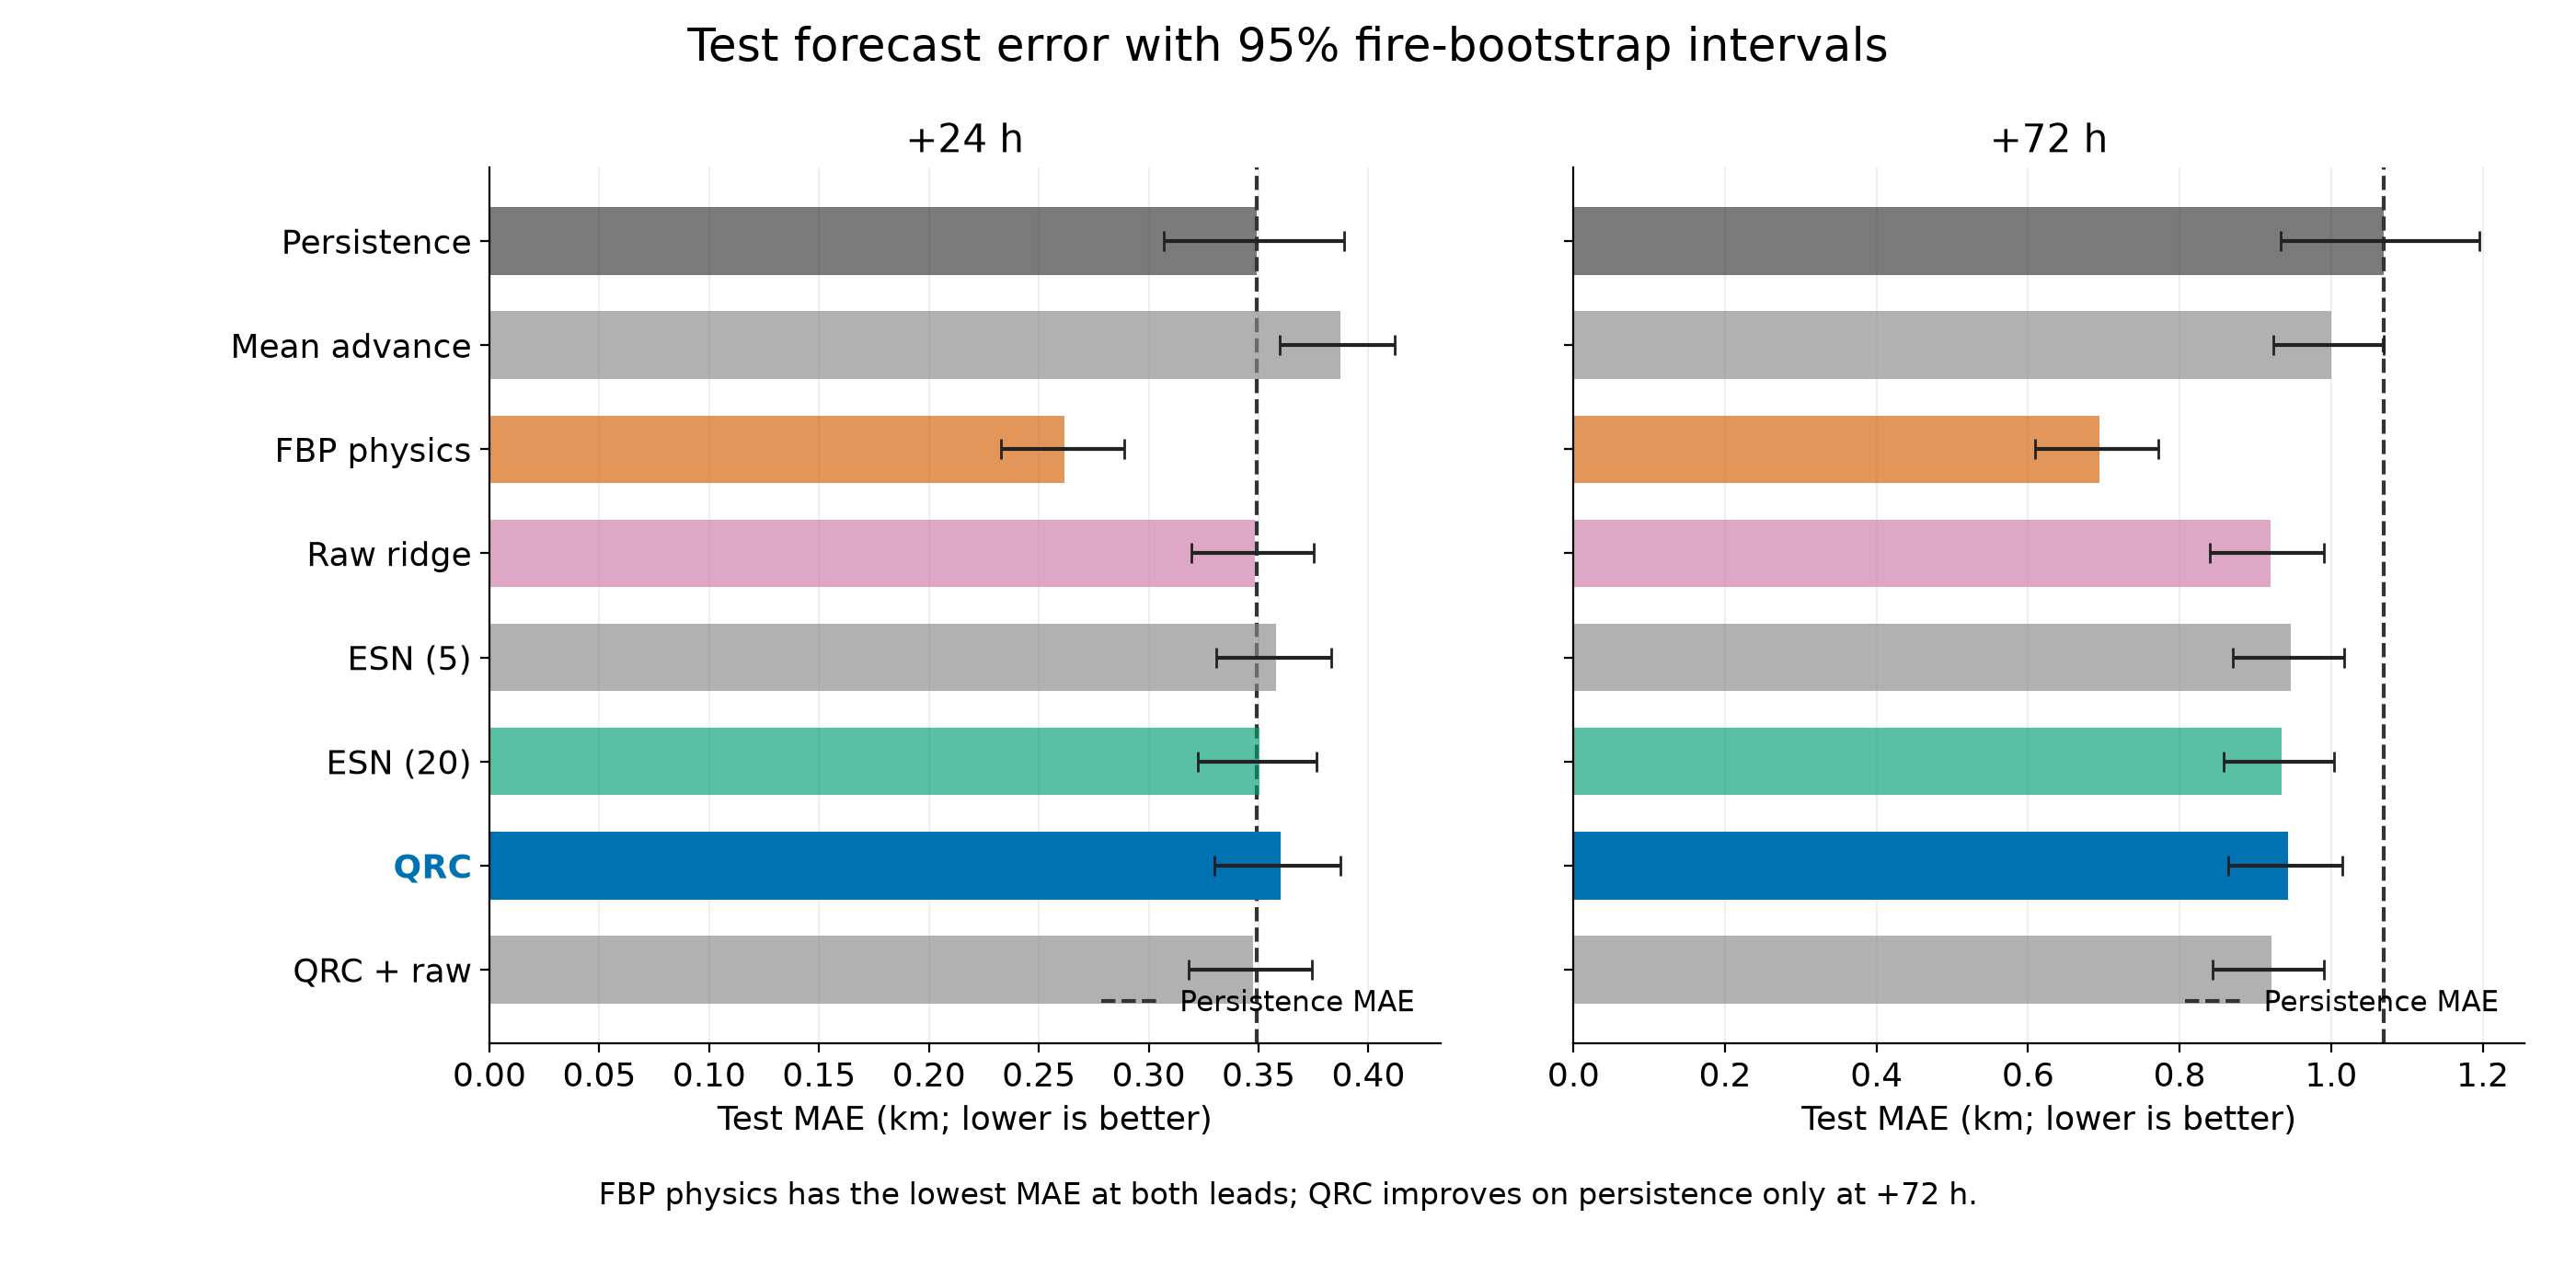

In [7]:
metrics = read_csv("results/metrics.csv")
test = metrics.loc[metrics.split.eq("test")].copy()
result_table = test[["model", "lead", "skill", "iou", "mae_growing"]].copy()
result_table["lead"] *= 24
result_table = result_table.rename(columns={"lead": "lead_h"})
result_table.insert(2, "mae [mae_lo, mae_hi]", [
    f"{row.mae:.6f} [{row.mae_lo:.6f}, {row.mae_hi:.6f}]"
    for row in test.itertuples()
])
display(result_table.sort_values(["lead_h", "model"]).reset_index(drop=True))
comparisons = read_csv("results/qrc_comparisons.csv")
comparisons["lead_h"] = comparisons.pop("lead") * 24
print("Paired MAE differences: reservoir minus reference; negative favours the reservoir.")
display(comparisons)
show_figure("e1_test_mae.png")

## Controls

E4 varies fixed circuit seeds; the table gives mean and sample standard
deviation of test MAE. E2 splits sectors by wind direction. E5 varies local
simulator shots and noise on the saved subset, with its exact MAE alongside.
E9 drops hotspot days and carries the last value forward. These checks use
the committed tables and keep the selected configuration fixed.

E4 — fixed-seed test MAE (km)


seeds  mae_mean   mae_sd
model lead                          
haar  1        10  0.360574 0.007301
      3        10  0.945931 0.015459
qrc   1         5  0.362390 0.008139
      3         5  0.949891 0.016248

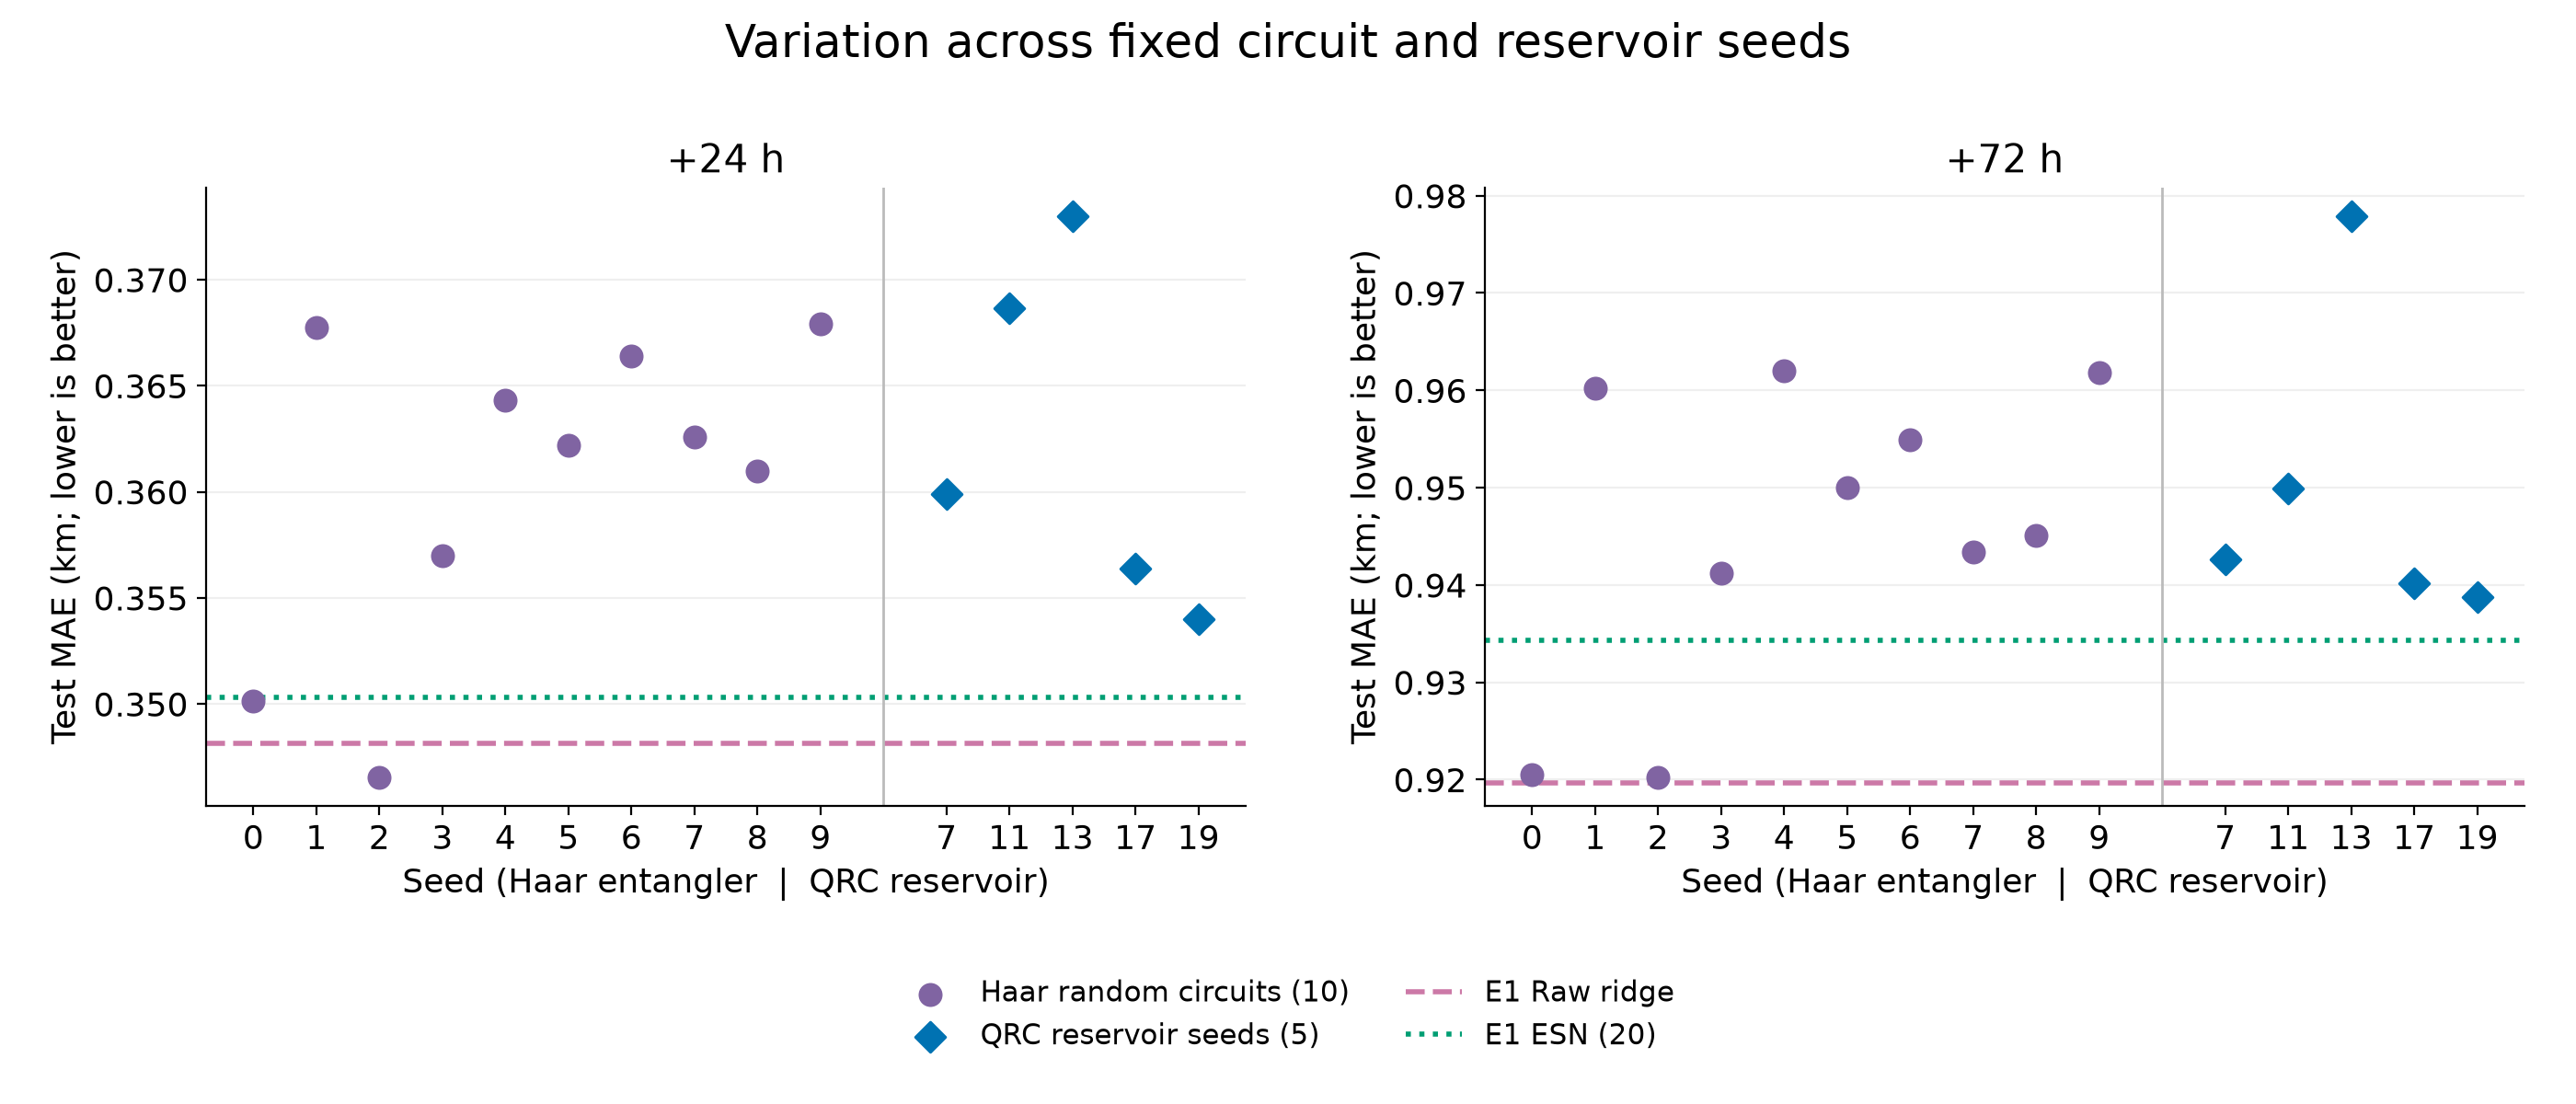

E2 — test MAE by wind bin (km); lead is in days


lead                         1        3
model       wind_bin                   
esn20       crosswind 0.322775 0.898927
            downwind  0.460195 1.076083
            upwind    0.267708 0.827765
fbp         crosswind 0.208375 0.607898
            downwind  0.405191 0.919101
            upwind    0.171419 0.554627
persistence crosswind 0.325135 1.004476
            downwind  0.444562 1.302125
            upwind    0.277086 0.902258
qrc         crosswind 0.334649 0.908947
            downwind  0.457917 1.069567
            upwind    0.286944 0.849157

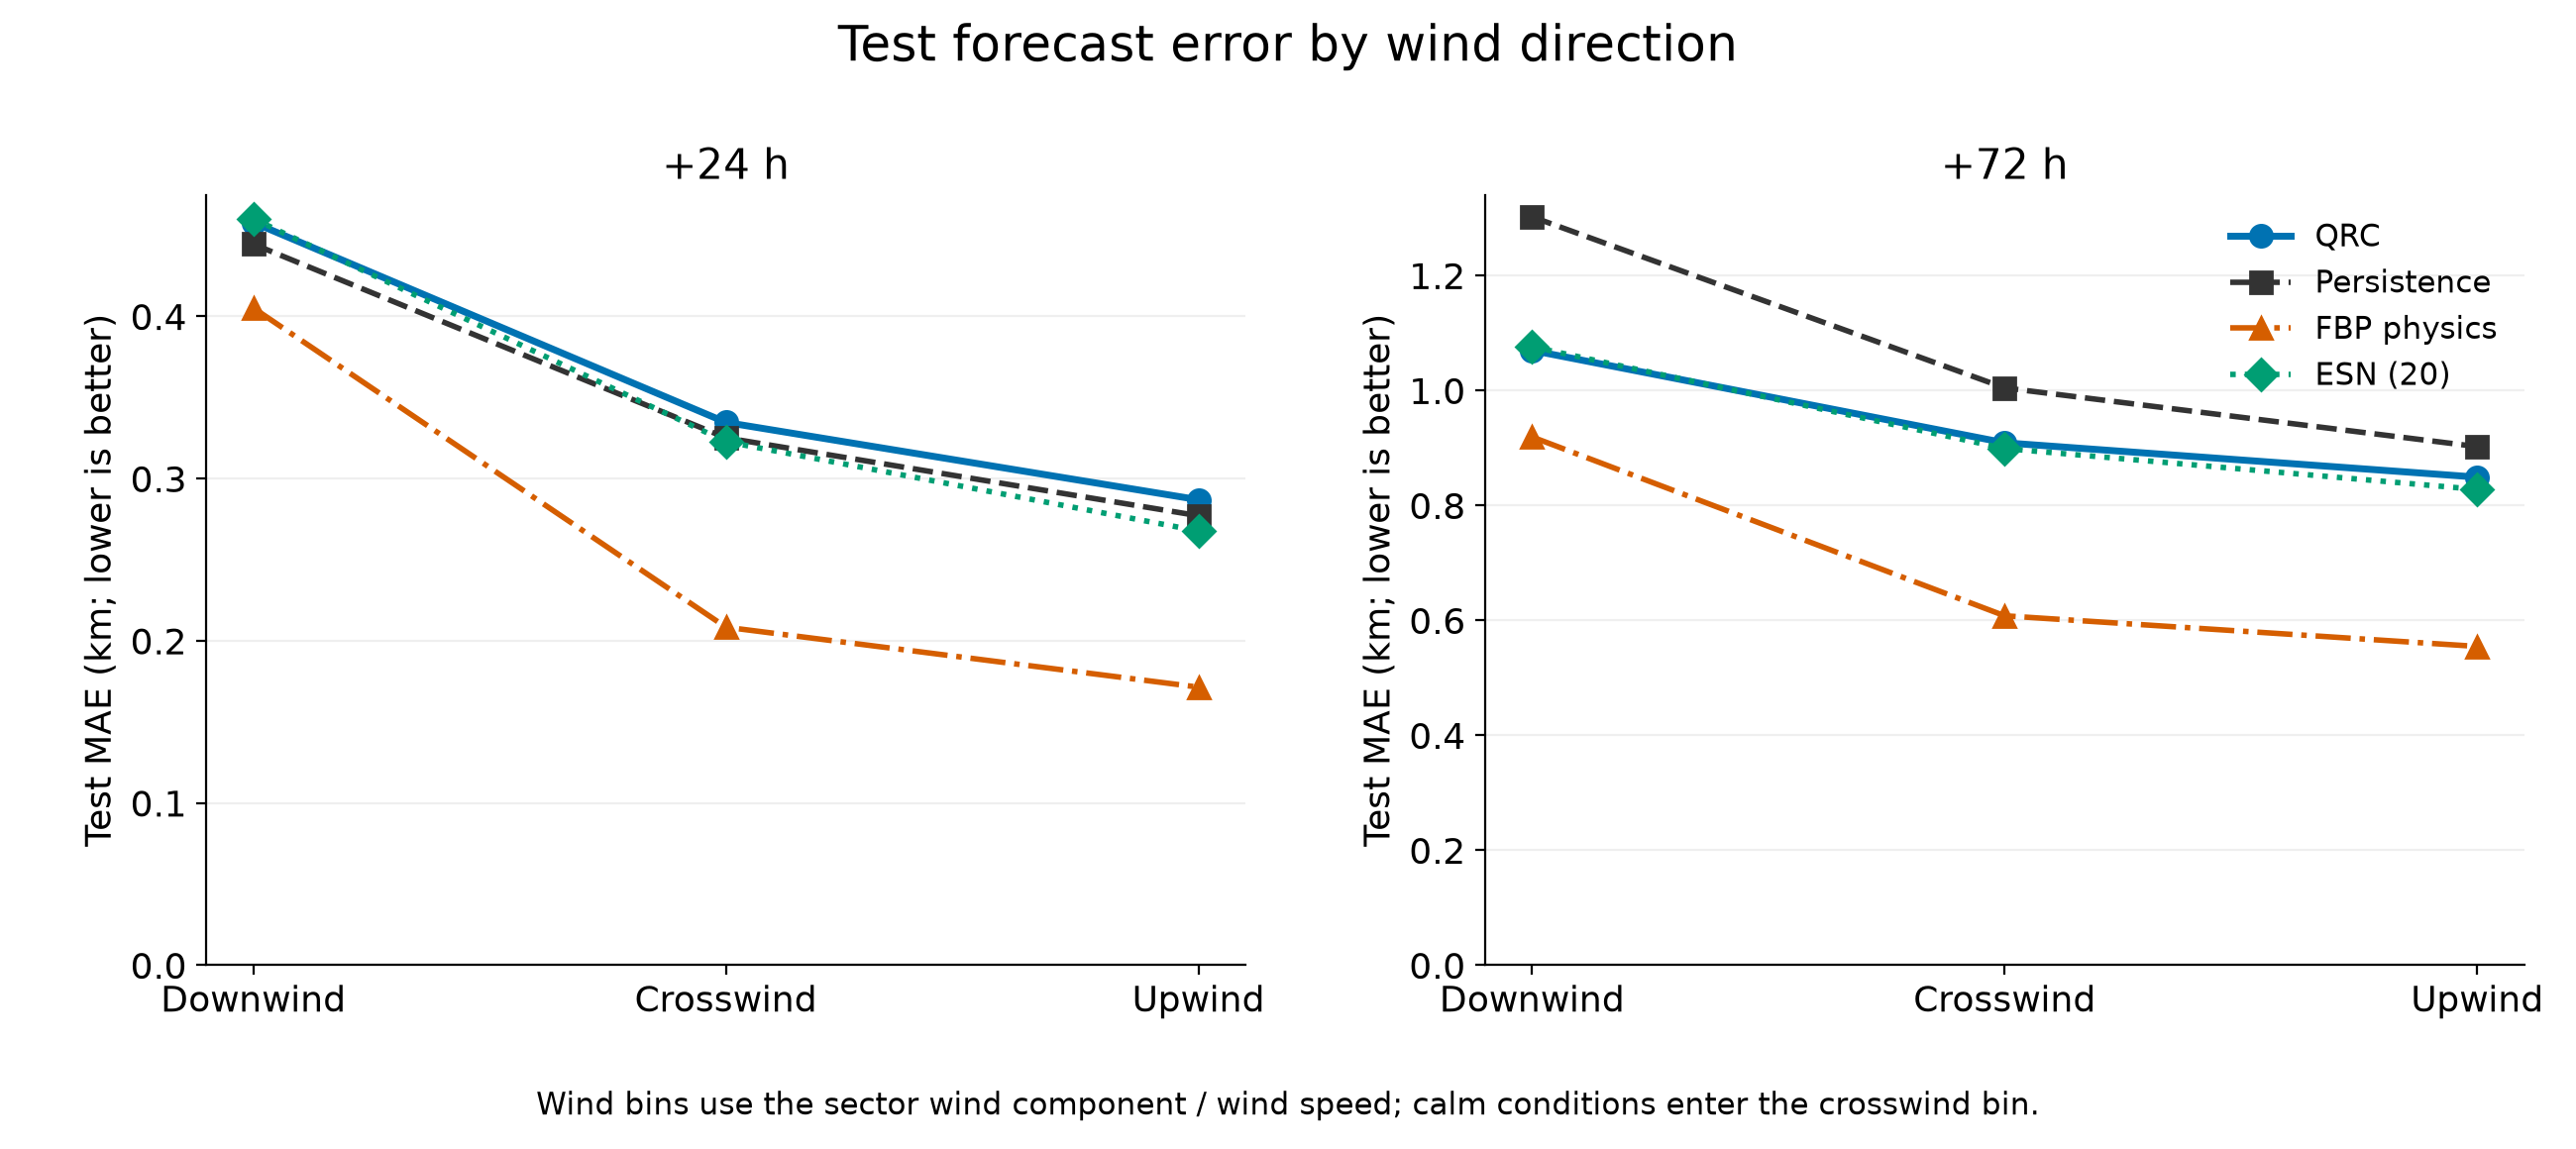

In [8]:
seeds = read_csv("results/e4_seeds.csv")
seeds = seeds.loc[seeds.split.eq("test")]
print("E4 — fixed-seed test MAE (km)")
display(seeds.groupby(["model", "lead"]).agg(
    seeds=("seed", "nunique"), mae_mean=("mae", "mean"), mae_sd=("mae", "std")
))
show_figure("e4_seeds.png")

wind = read_csv("results/e2_wind.csv")
print("E2 — test MAE by wind bin (km); lead is in days")
display(wind.pivot(index=["model", "wind_bin"], columns="lead", values="mae"))
show_figure("e2_wind.png")

In [9]:
shots = read_csv("results/e5_shots.csv")
print("E5 — sampled / exact MAE (km) on the same subset; lead is in days")
display(shots.pivot(index=["shots", "noise"], columns="lead", values=["mae", "mae_exact", "n_rows"]))

sparse = read_csv("results/e9_sparse.csv")
print("E9 — test MAE (km) as hotspot days are removed; lead is in days")
display(sparse.pivot(index=["drop_frac", "model"], columns="lead", values="mae"))

E5 — sampled / exact MAE (km) on the same subset; lead is in days


mae          mae_exact               n_rows            
lead                  1        3         1        3           1           3
shots noise                                                                
100   fake_fez 1.227445 2.863999  0.359182 0.933964 2036.000000 1953.000000
      ideal    1.212296 2.824454  0.359182 0.933964 2036.000000 1953.000000
1000  fake_fez 0.521288 1.296415  0.359182 0.933964 2036.000000 1953.000000
      ideal    0.587455 1.400993  0.359182 0.933964 2036.000000 1953.000000
2000  fake_fez 0.453460 1.143627  0.359182 0.933964 2036.000000 1953.000000
      ideal    0.503036 1.226322  0.359182 0.933964 2036.000000 1953.000000
10000 fake_fez 0.336619 0.905716  0.359182 0.933964 2036.000000 1953.000000
      ideal    0.405059 1.011671  0.359182 0.933964 2036.000000 1953.000000

E9 — test MAE (km) as hotspot days are removed; lead is in days


lead                         1        3
drop_frac model                        
0.000000  esn20       0.350293 0.934348
          fbp         0.261797 0.694097
          persistence 0.348986 1.069785
          qrc         0.359898 0.942642
0.150000  esn20       0.377358 0.983962
          fbp         0.271845 0.717393
          persistence 0.394420 1.160988
          qrc         0.384278 0.989753
0.300000  esn20       0.384959 1.014235
          fbp         0.266770 0.725146
          persistence 0.441546 1.299062
          qrc         0.384490 1.007522
0.450000  esn20       0.344167 0.910056
          fbp         0.230404 0.648513
          persistence 0.439432 1.294322
          qrc         0.347080 0.925718

## Real hardware (E6)

The saved job ran Z-basis circuits on ibm_fez. The table below compares its
features with exact simulation, local FakeFez simulation and persistence.
All feature sources use the same frozen, exact-trained Z-only read-out.
This is one fire with 88 correlated sector windows: the comparison is descriptive.

For the local recomputation, targets come from `results/e6_predictions.csv`
and are joined by date and sector to `hardware/zf015_case.npz` archive order.
The saved scaler maps raw inputs before circuit encoding; the hardware file
already contains measured Z/ZZ features, so these go directly into the saved
ridge coefficients and intercept, followed by the saved lower clipping bound.

In [10]:
job_metrics = read_json("hardware/e6_job_metrics.json")
meta = read_json("results/e6_meta.json")
jobs = read_json("hardware/jobs.json")
job = next(row for row in jobs if row["job_id"] == job_metrics["job_id"])
assert meta["job_id"] == job["job_id"]
assert meta["backend"] == job["backend"]
assert meta["shots"] == job["budget"]["shots"]
display(pd.DataFrame([{
    "job_id": job_metrics["job_id"],
    "backend": meta["backend"],
    "shots_per_circuit": meta["shots"],
    "circuits": len(W),
    "qpu_seconds": job_metrics["usage"]["qpu_charge_time_seconds"],
}]))

,job_id,backend,shots_per_circuit,circuits,qpu_seconds
0,dbm0tm58ft8s738tu920,ibm_fez,10000,88,238


E6 +24 h absolute MAE difference: 0.000000000000e+00 km
E6 +72 h absolute MAE difference: 0.000000000000e+00 km


,lead_h,recomputed_mae,saved_mae,absolute_difference
0,24,0.257881,0.257881,0.000000
1,72,0.979314,0.979314,0.000000


,source,lead,mae,n_rows,feature_mae
0,exact,1,0.272408,88,0.000000
1,fake_fez,1,0.277193,88,0.043793
2,hardware,1,0.257881,88,0.072526
3,persistence,1,0.300678,88,NaN
4,exact,3,1.001495,88,0.000000
5,fake_fez,3,1.005559,88,0.043793
6,hardware,3,0.979314,88,0.072526
7,persistence,3,1.228193,88,NaN


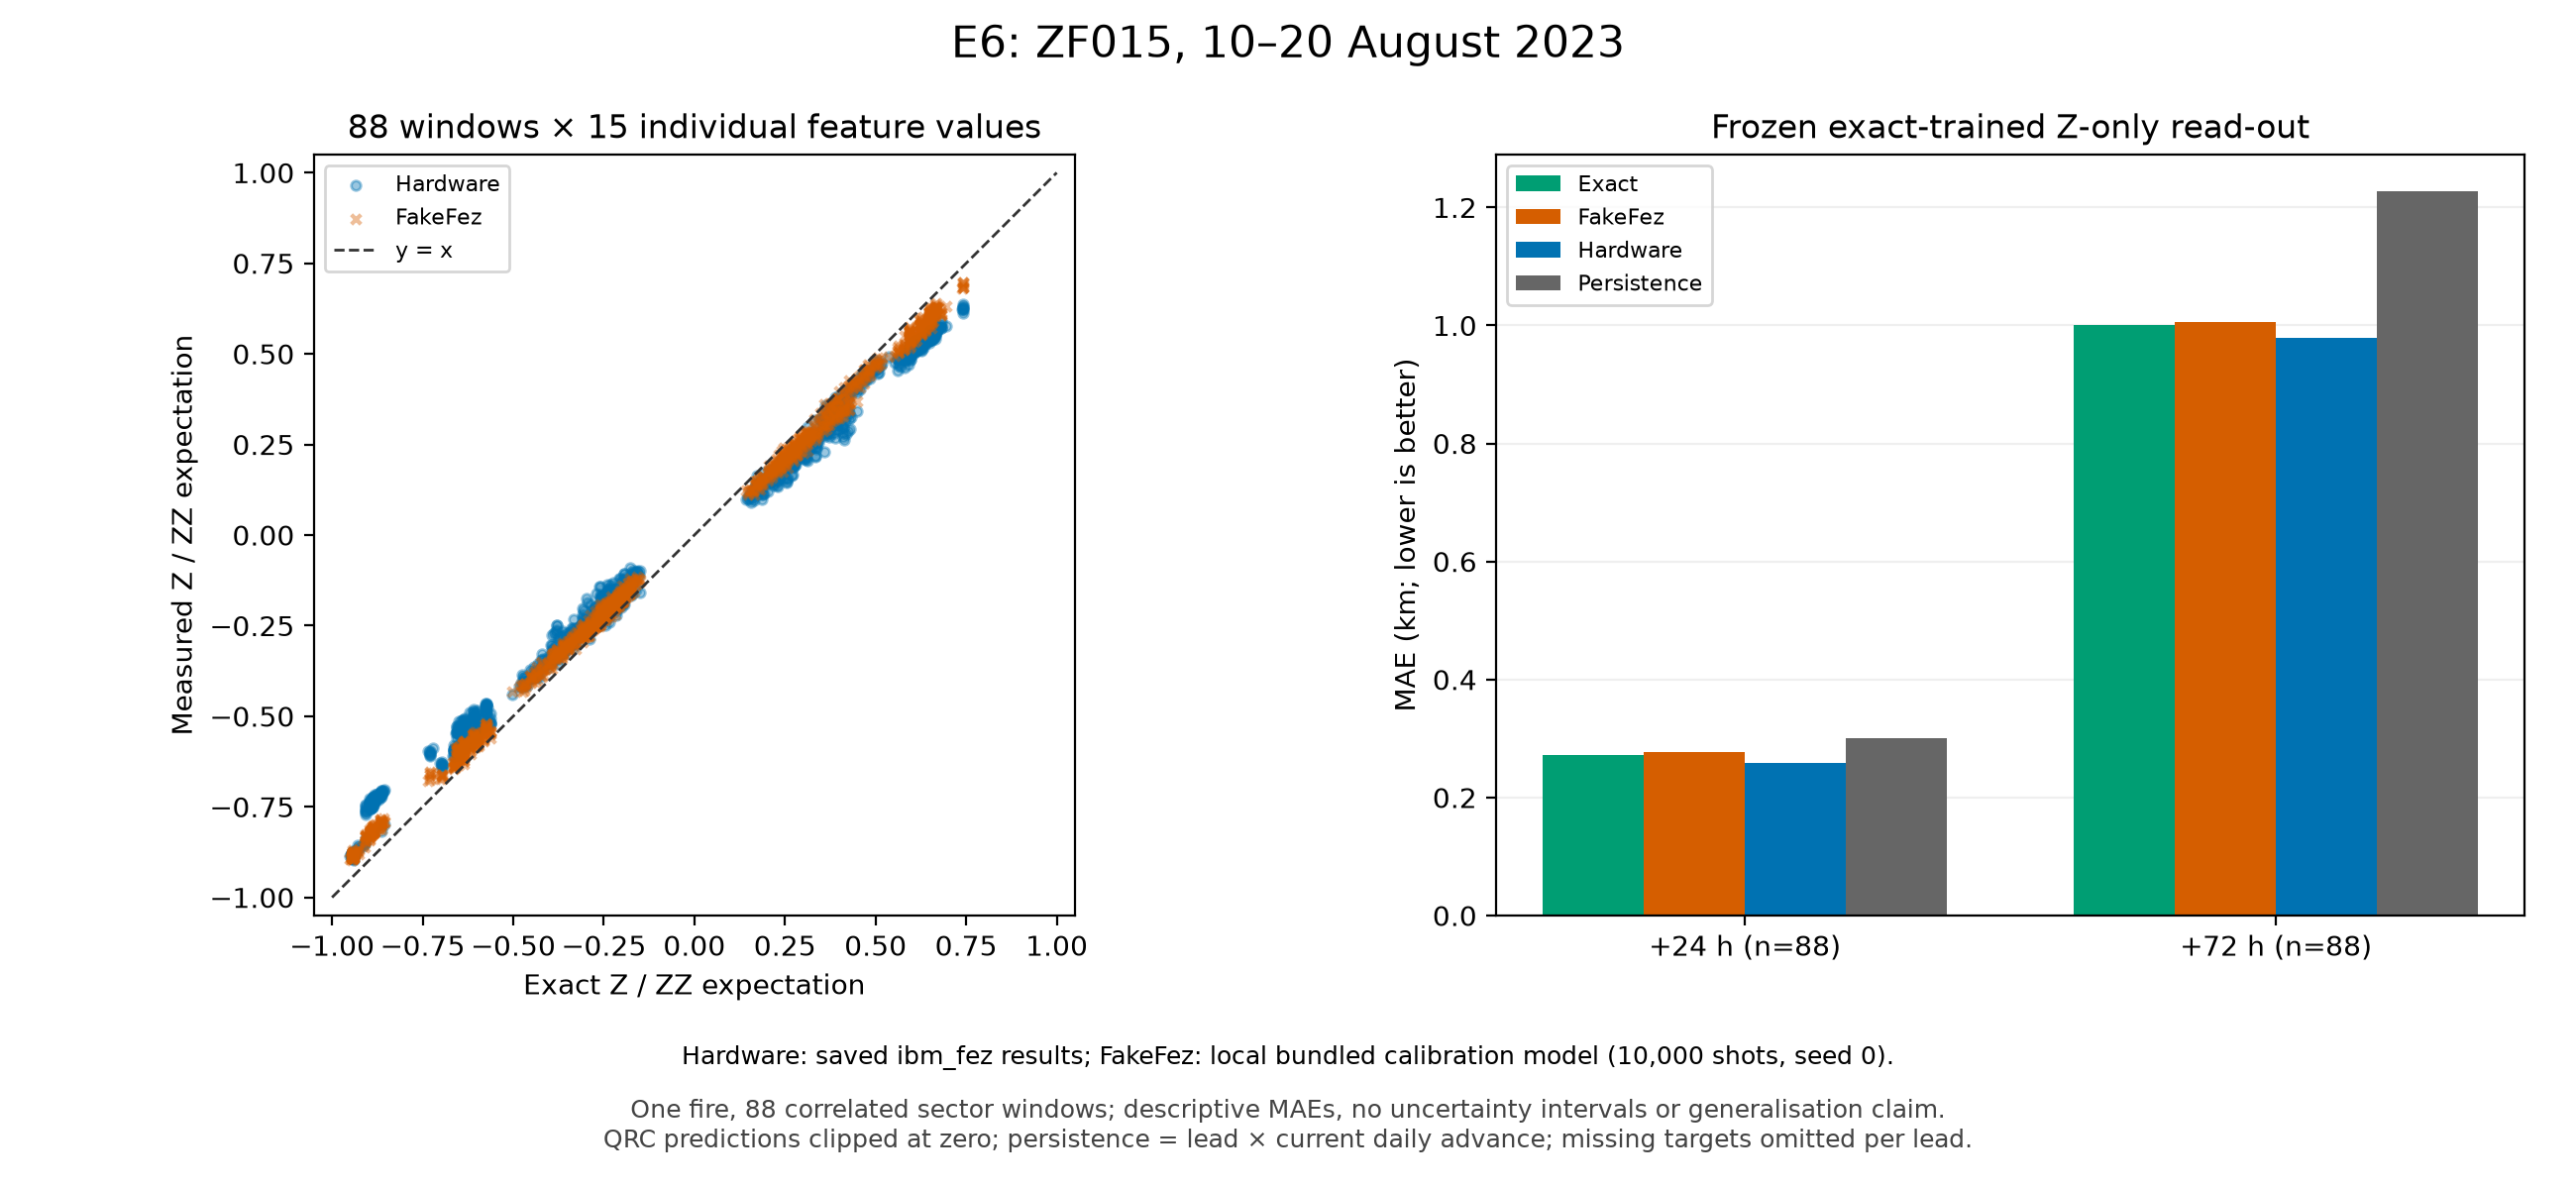

In [11]:
# E6 live recomputation from measured features and frozen weights.
readout = read_json("results/qrc_z_readout.json")
measured = load_array("hardware/e6_hw_features.npy")
assert measured.shape == (len(W), len(readout["feature_names"]))
assert readout["feature_names"] == names[:measured.shape[1]]
assert np.isfinite(measured).all()
assert np.all((W >= 0) & (W <= 1))
assert len(readout["scaler"]["lo"]) == W.shape[-1]
saved_predictions = read_csv("results/e6_predictions.csv", parse_dates=["date"])
hardware_scores = read_csv("results/e6_hardware.csv")
checks = []
for lead in (1, 3):
    fit = readout["readouts"][str(lead)]
    predicted = np.maximum(
        measured @ np.asarray(fit["coefficients"]) + fit["intercept"],
        readout["prediction_clip_min"],
    )
    targets = saved_predictions.loc[saved_predictions.lead.eq(lead), ["date", "sector", "y"]]
    joined = case_rows.assign(yhat=predicted).merge(
        targets, on=["date", "sector"], how="left", sort=False, validate="one_to_one"
    )
    keep = joined.y.notna()
    reference = hardware_scores.loc[
        hardware_scores.source.eq("hardware") & hardware_scores.lead.eq(lead)
    ].iloc[0]
    assert int(keep.sum()) == int(reference.n_rows)
    recomputed = mae(joined.loc[keep, "y"], joined.loc[keep, "yhat"])
    difference = abs(recomputed - reference.mae)
    print(f"E6 +{lead * 24} h absolute MAE difference: {difference:.12e} km")
    assert difference < 1e-9
    checks.append({"lead_h": lead * 24, "recomputed_mae": recomputed,
                   "saved_mae": reference.mae, "absolute_difference": difference})
display(pd.DataFrame(checks))
display(hardware_scores)
show_figure("e6_hardware.png")

## ZF015 / Yellowknife case

The map compares dated reconstructed outlines and forecasts with the official
season-end perimeter. Yellowknife's centre distance and sector below come from
`results/e8_eta.json`. The single-sector time-to-reach is not meaningful here:
the closest approach is through the south lobe, sector 4, about 25 km away.
A single-sector time-to-reach is not reported.

Yellowknife: 66.7 km from the fire centre, sector 3.


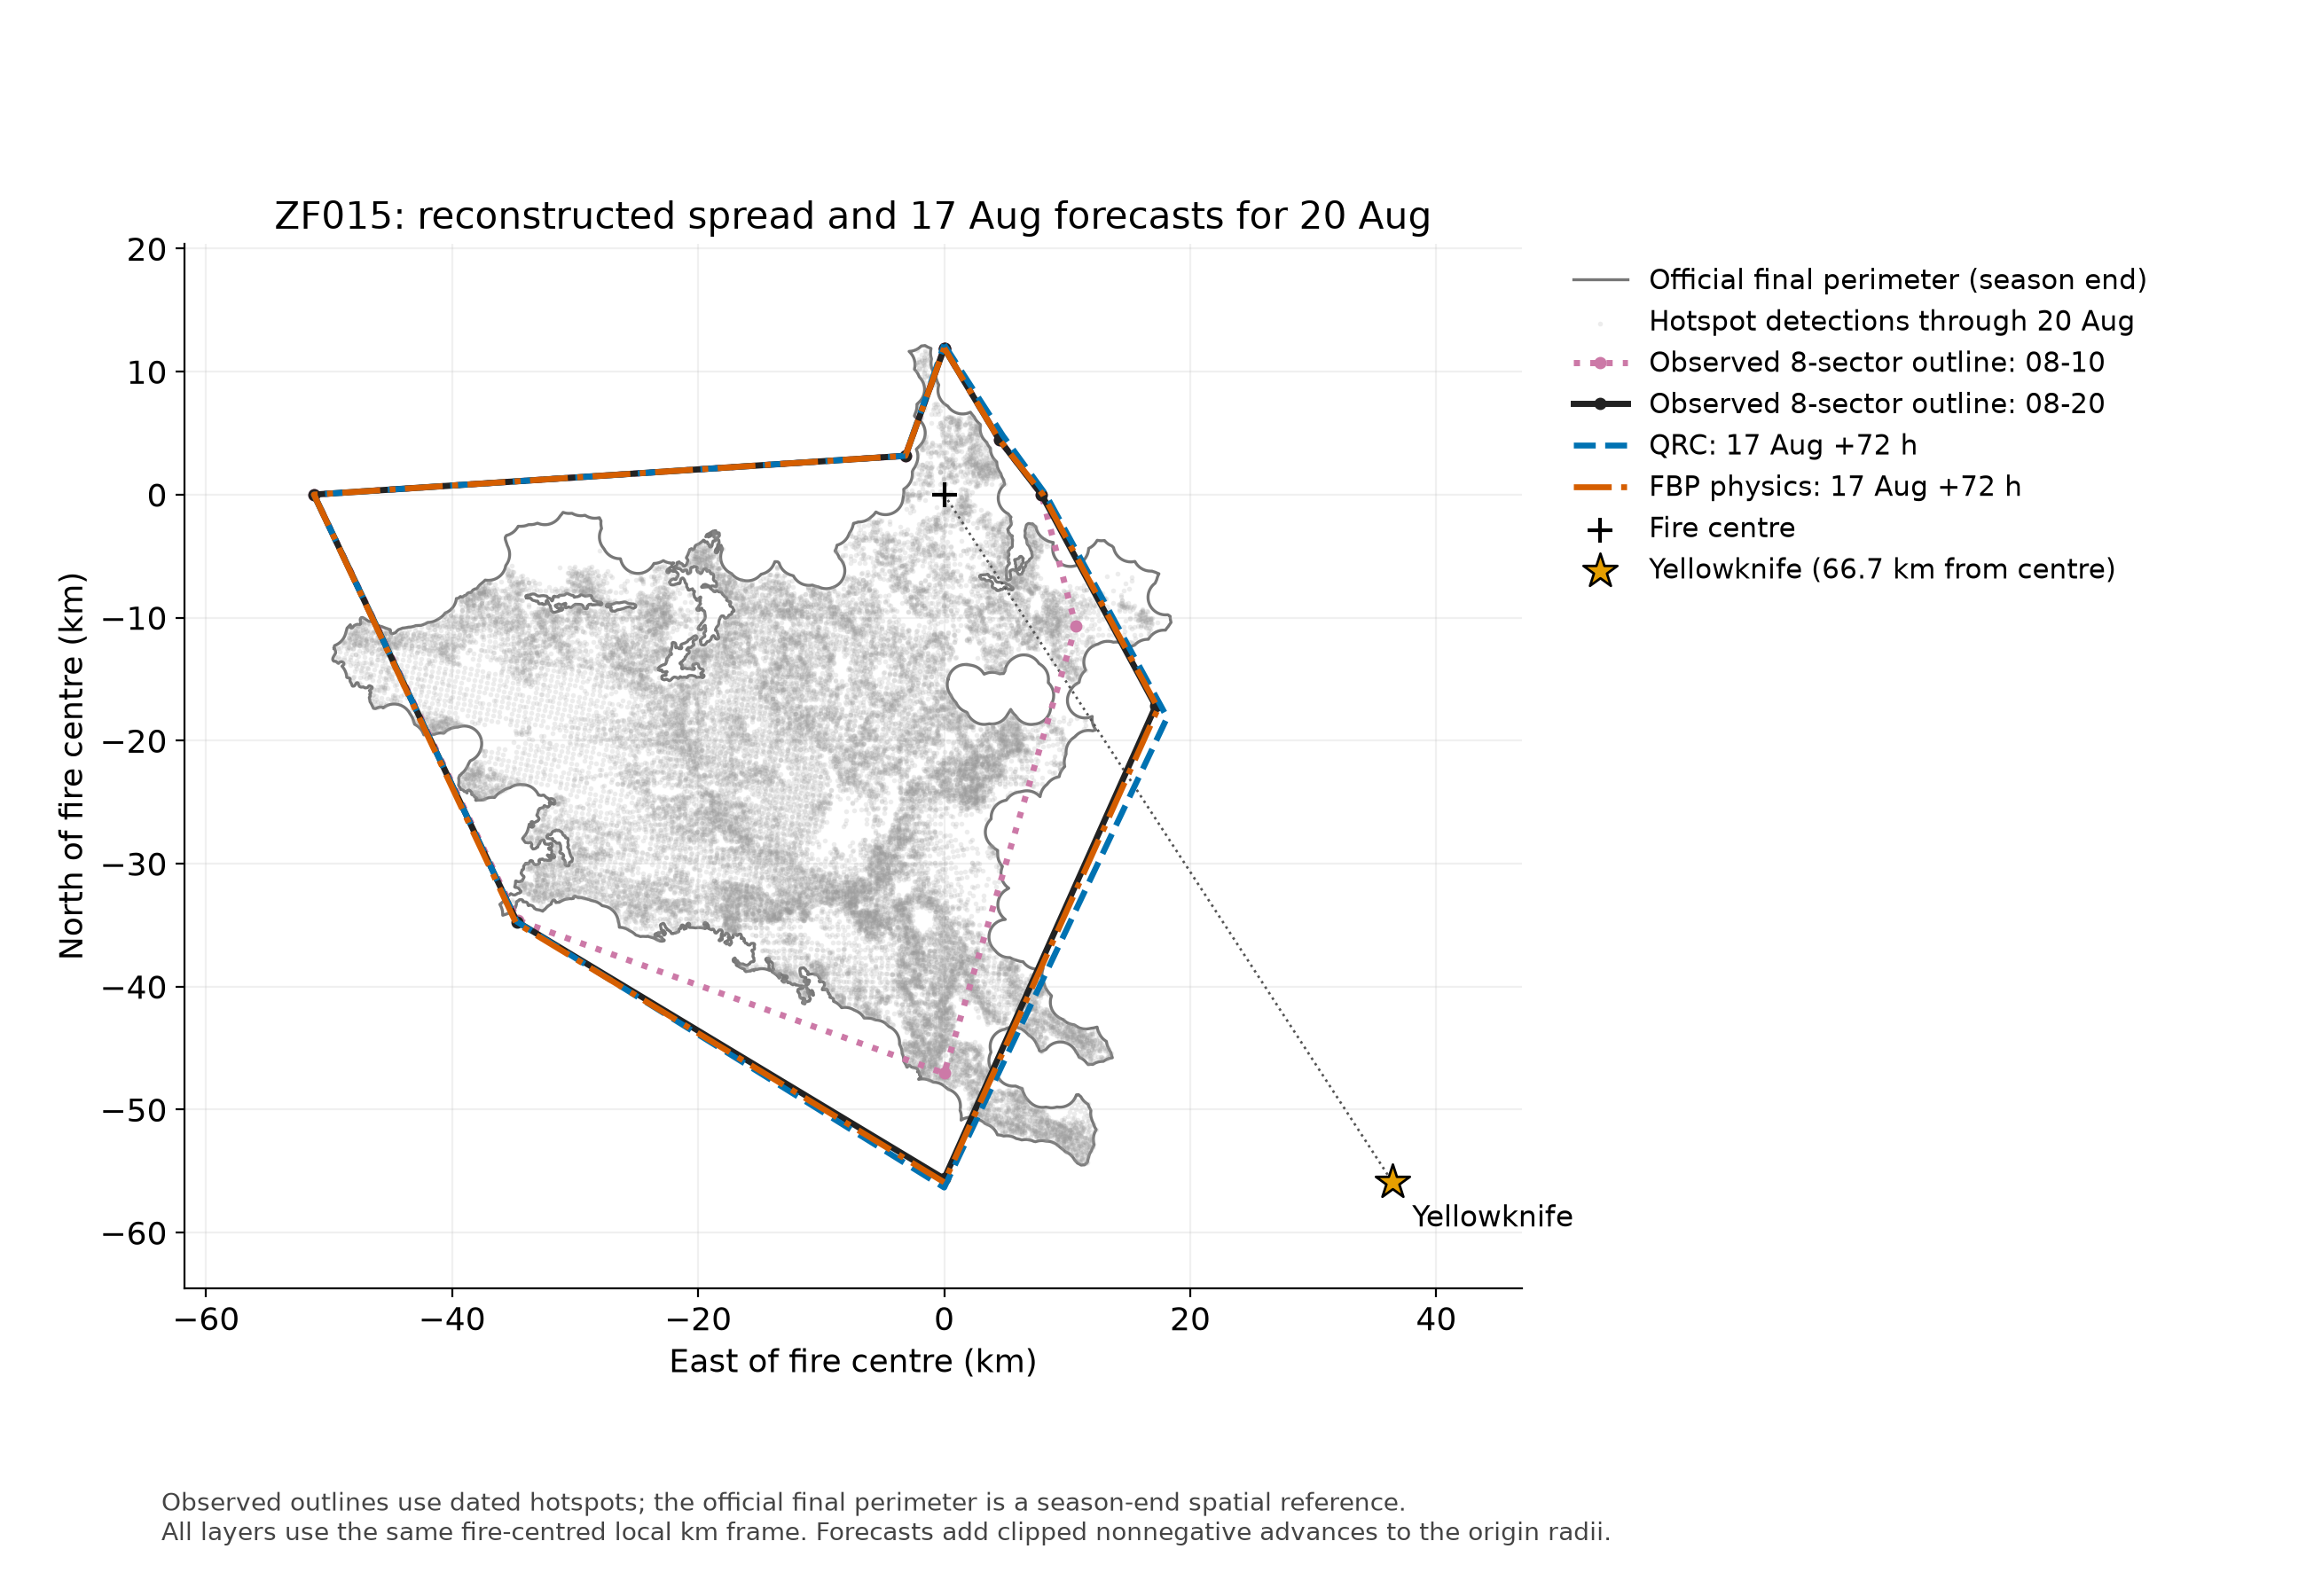

In [12]:
location = read_json("results/e8_eta.json")
print(f"{location['town']}: {location['distance_km']:.1f} km from the fire centre, sector {location['sector']}.")
show_figure("e8_zf015_map.png")

## More qubits and inputs (after freezing)

After the study was frozen, we tried larger circuits. These runs are exploratory and
do not change the results above. The chart shows 2022 validation MAE (lower is better);
larger circuits that only copy the same 5 inputs onto extra qubits are left out.

- **16 qubits (ring):** 2 qubits per sector, all 8 sectors linked to their neighbours.
- **7 qubits (+terrain +fuel):** adds upslope toward the sector and conifer share.
- **10 qubits (+future weather\*):** also adds regional wind toward the sector, ISI and
  rain for the forecast days (+24 h: the next day; +72 h: the next three days).
  \*This uses the weather that was later observed, so it assumes a perfect weather
  forecast; the fire's own hotspots are removed from it.

Each group compares the quantum reservoir, a classical reservoir (ESN) of the same
size, and ridge on the same inputs. To make the comparison fair, the quantum and
classical reservoirs get the same budget: 3 settings each (quantum: rotation scale
γ = π/4, π/2, 3π/4; ESN: input scale 0.3, 1, 3), each run with 5 random seeds.
The setting with the best 5-seed mean on 2022 is kept, and its seed mean is reported;
the thin lines span the seeds. The 16-qubit ring was run once, with γ picked on the
same 2022 fires, so its bar is optimistic. The tables below also give 2023 scores.
2023 had already been used by the frozen study, so these are a post-hoc second look,
not a new test.

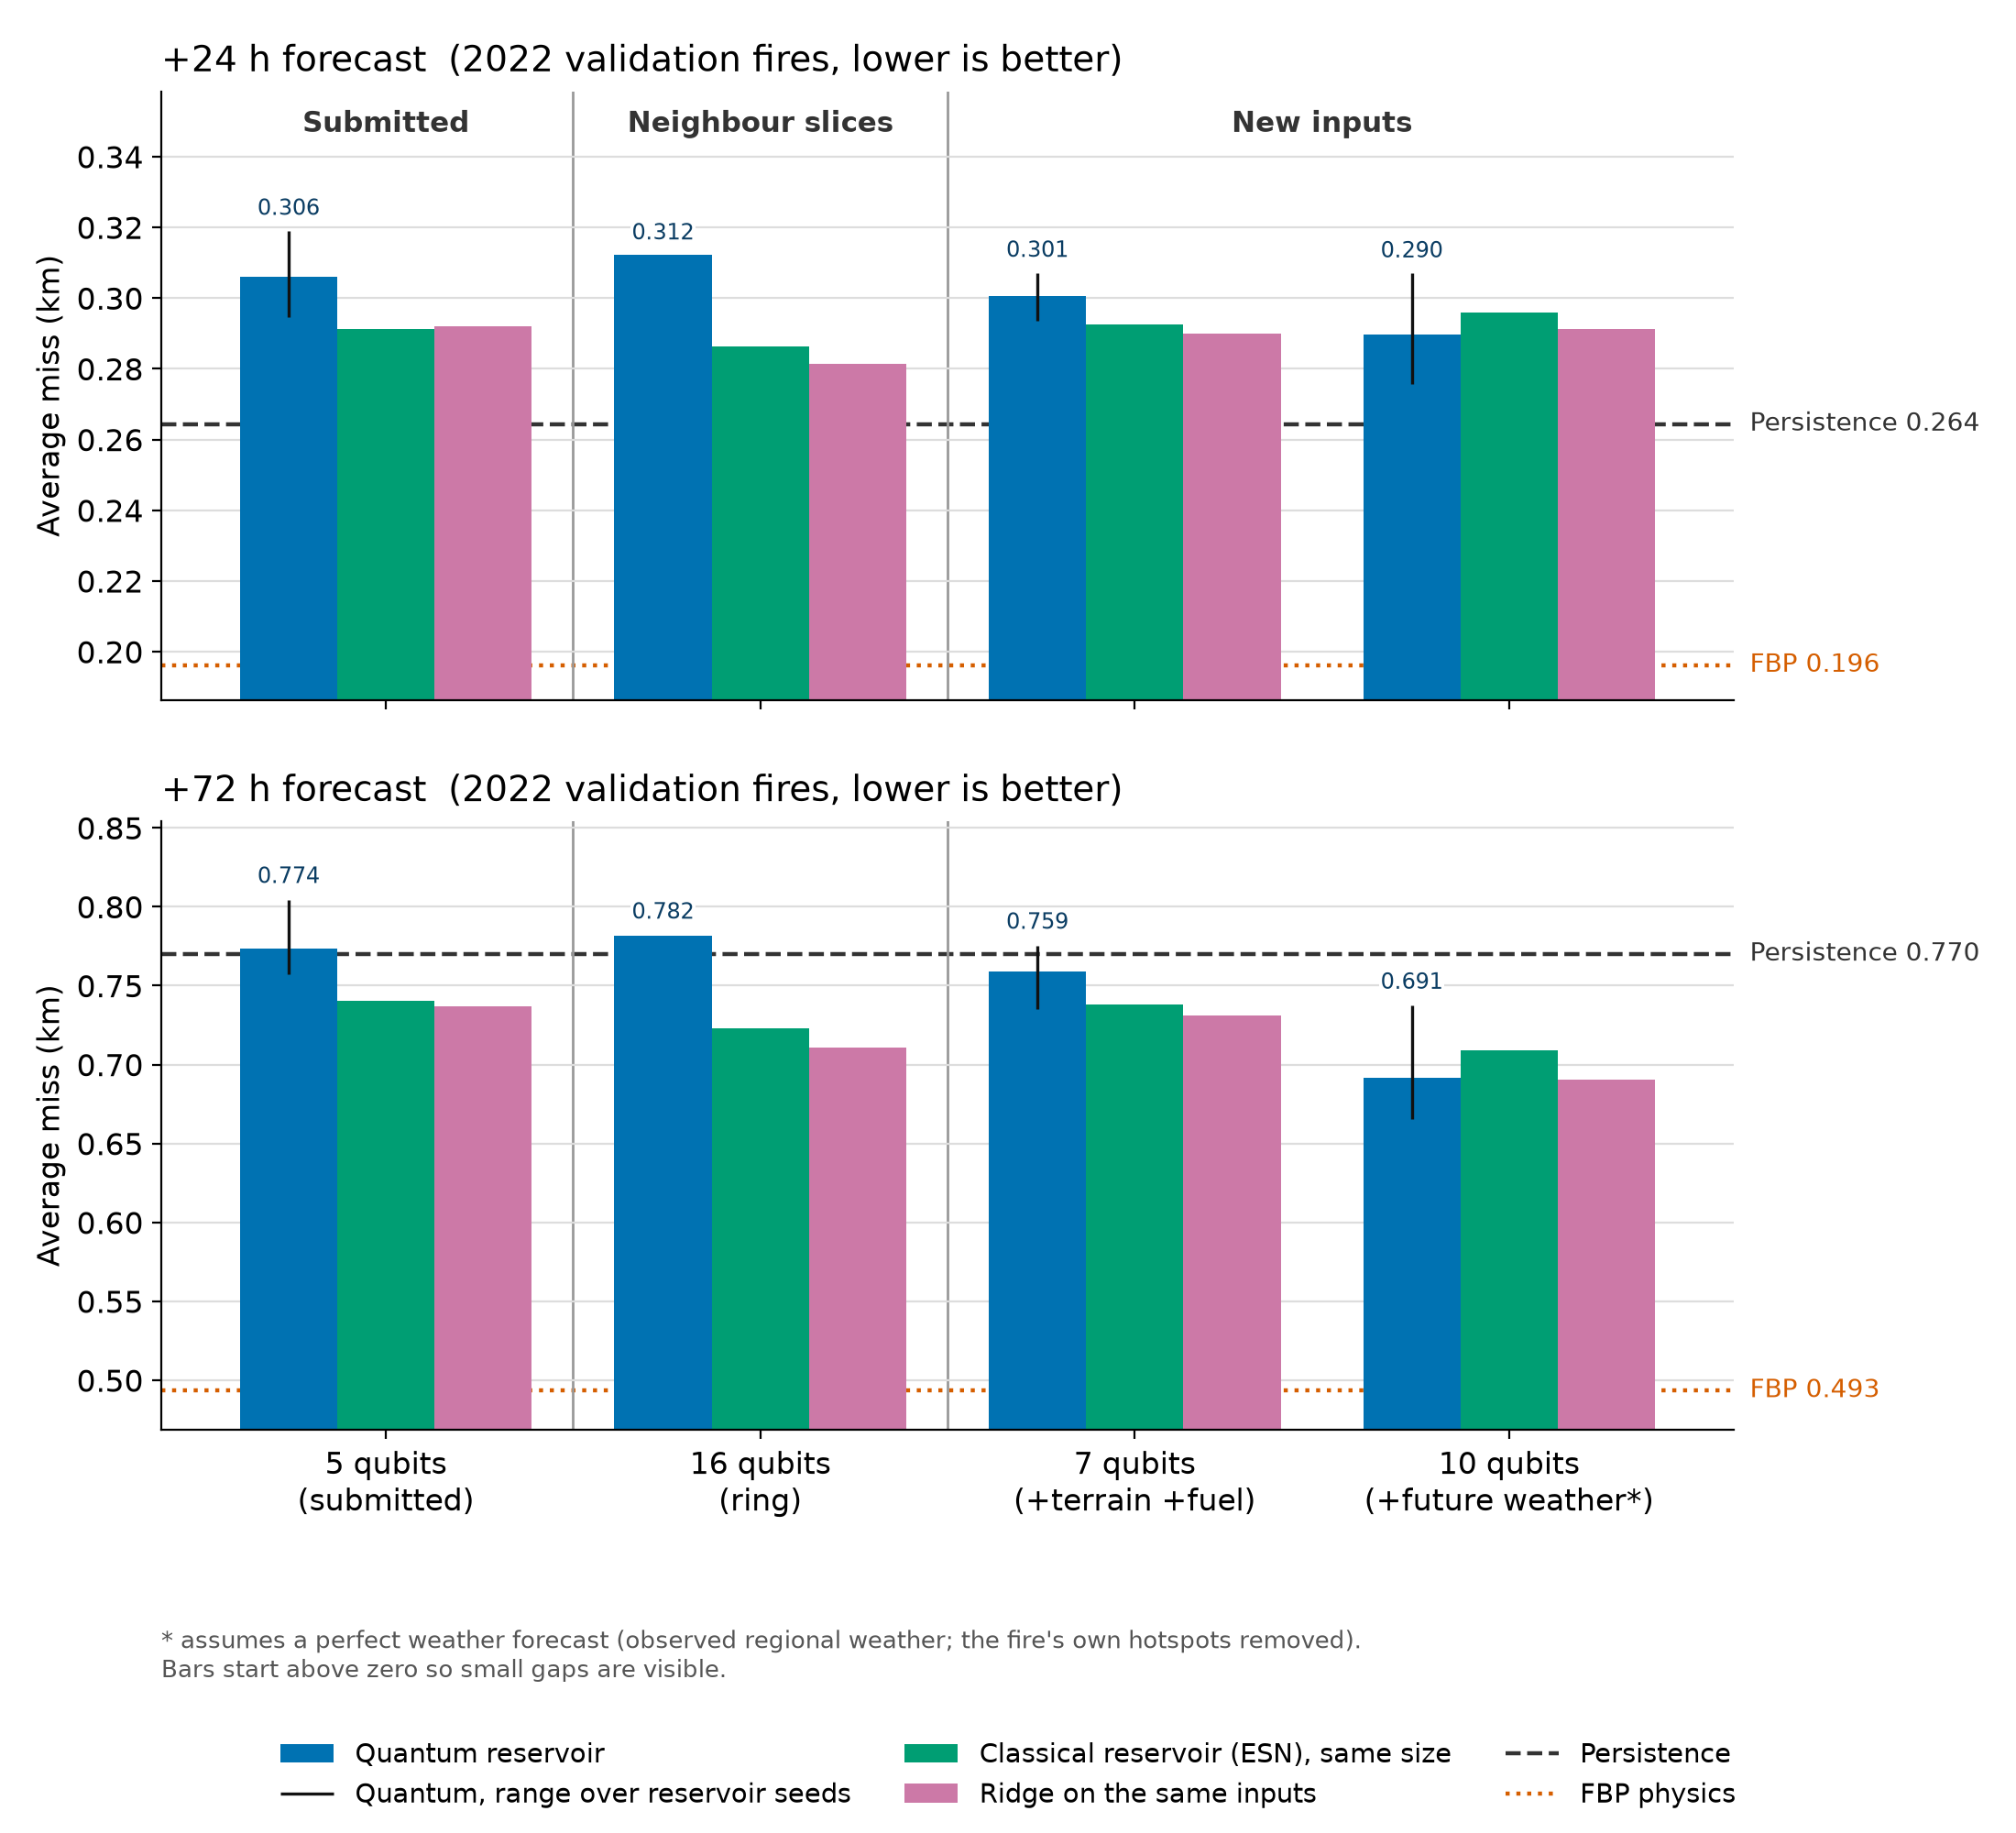

MAE (km): mean [min-max] over 5 seeds, for the setting chosen on 2022


,version,model,lead_h,setting,val 2022,2023 (post-hoc)
0,5 qubits (submitted),quantum,24,gamma=0.25pi,0.306 [0.295-0.319],0.362 [0.354-0.373]
1,5 qubits (submitted),ESN,24,input_scale=0.3,0.291 [0.289-0.293],0.347 [0.346-0.350]
2,5 qubits (submitted),ridge,24,raw,0.292,0.348
3,7 qubits (+terrain +fuel),quantum,24,gamma=0.25pi,0.301 [0.294-0.307],0.357 [0.351-0.362]
4,7 qubits (+terrain +fuel),ESN,24,input_scale=0.3,0.293 [0.291-0.294],0.348 [0.343-0.355]
5,7 qubits (+terrain +fuel),ridge,24,raw,0.290,0.342
6,10 qubits (+future weather),quantum,24,gamma=0.25pi,0.290 [0.276-0.307],0.348 [0.338-0.358]
7,10 qubits (+future weather),ESN,24,input_scale=0.3,0.296 [0.294-0.299],0.351 [0.347-0.353]
8,10 qubits (+future weather),ridge,24,raw,0.291,0.342
9,5 qubits (submitted),quantum,72,gamma=0.25pi,0.774 [0.757-0.804],0.950 [0.939-0.978]


Paired 2023 differences in seed-averaged error (km), 95% fire bootstrap; negative favours the first model.


,version,lead_h,comparison,diff,lo,hi
0,5 qubits (submitted),24,quantum minus ridge,0.014261,0.012818,0.015597
1,5 qubits (submitted),24,quantum minus ESN,0.015161,0.013899,0.016406
2,5 qubits (submitted),24,ESN minus ridge,-0.000900,-0.001373,-0.000450
3,5 qubits (submitted),72,quantum minus ridge,0.030187,0.025896,0.034231
4,5 qubits (submitted),72,quantum minus ESN,0.027373,0.023075,0.031253
5,5 qubits (submitted),72,ESN minus ridge,0.002814,0.001909,0.003790
6,7 qubits (+terrain +fuel),24,quantum minus ridge,0.014375,0.012541,0.016272
7,7 qubits (+terrain +fuel),24,quantum minus ESN,0.009036,0.007116,0.010989
8,7 qubits (+terrain +fuel),24,ESN minus ridge,0.005339,0.004005,0.006694
9,7 qubits (+terrain +fuel),72,quantum minus ridge,0.034589,0.030375,0.039066


In [13]:
show_figure("qubit_comparison.png")
labels = {"base5": "5 qubits (submitted)", "A7": "7 qubits (+terrain +fuel)",
          "B10_h": "10 qubits (+future weather)"}
names = {"qrc": "quantum", "esn": "ESN", "raw": "ridge"}
selected = read_csv("results/e14_selected.csv")

def span(row, split):
    mean, lo, hi = row[f"{split}_mean"], row[f"{split}_min"], row[f"{split}_max"]
    return f"{mean:.3f}" if row.n_seeds == 1 else f"{mean:.3f} [{lo:.3f}-{hi:.3f}]"

table = pd.DataFrame({"version": selected.version.map(labels), "model": selected.family.map(names),
                      "lead_h": selected.lead * 24, "setting": selected.config,
                      "val 2022": selected.apply(span, axis=1, split="val"),
                      "2023 (post-hoc)": selected.apply(span, axis=1, split="test")})
print("MAE (km): mean [min-max] over 5 seeds, for the setting chosen on 2022")
display(table.sort_values("lead_h", kind="stable").reset_index(drop=True))
paired = read_csv("results/e14_paired.csv")
paired = paired.loc[paired.split.eq("test")].assign(
    version=lambda d: d.version.map(labels), lead_h=lambda d: d.lead * 24,
    comparison=lambda d: d.model.map(names) + " minus " + d.reference.map(names))
print("Paired 2023 differences in seed-averaged error (km), 95% fire bootstrap; "
      "negative favours the first model.")
display(paired[["version", "lead_h", "comparison", "diff", "lo", "hi"]].reset_index(drop=True))

With an equal tuning budget and 5 seeds each, ridge on the raw inputs is best or within
0.001 km of the best everywhere. At 5 and 7 qubits the quantum reservoir is worse than both ridge and the
tuned ESN at both leads, on 2022 and 2023 (every interval excludes 0). At 10 qubits
with future weather it ties ridge on 2022 and beats the ESN; on 2023 it is worse than
ridge (+0.006 km at +24 h, +0.027 km at +72 h) and slightly better than the ESN
(-0.003 and -0.008 km). That small edge over a tuned ESN is the only quantum gain left.
Quantum scores vary a lot with the seed (10 qubits, 2022, +24 h: 0.276 to 0.307 km).
Both reservoirs picked the smallest setting tried (γ = π/4, input scale 0.3), so a
wider grid might move them. A perfect weather forecast is not available in practice,
so the 10-qubit result is a best case.

## Conclusions and limits

- On 2023 test fires the quantum reservoir is about level with classical reservoirs
  and a random circuit, slightly behind ridge on the raw inputs. No quantum advantage is claimed.
- No model wins every measure: FBP physics has the lowest mean error; persistence
  has the best outline overlap (most sectors do not move); on growing sectors
  all learned models beat FBP and persistence.
- The reservoir beats persistence only at +72 h.
- On real ibm_fez hardware the forecasts survive the noise: MAE within about
  0.02 km of the exact simulation on one fire (88 correlated windows; descriptive only).
- Limits: one hardware case; the 30 km/day cap can creep for merged fires;
  inputs exclude fuel type, which FBP uses.

### Reproduce

To rebuild the full experiment, provide the source data described in the
README section 'Rebuild everything from the raw data', then run these scripts in order from the repository root:

1. `scripts/build_sectors.py`
2. `scripts/run_experiments.py`
3. `scripts/run_u5b.py`
4. `scripts/make_figures.py`
5. `scripts/e6_hardware.py`
6. `scripts/build_notebook.py`

Run each with `.venv/bin/python -I`. The E6 script reads the saved hardware
features. `scripts/build_notebook.py` rebuilds this notebook: it embeds the
saved inputs and runs it in an empty folder to check that it needs no other files.